In [1]:
### first we need a bit of import boilerplate

import os

# Avoids HDF5 file-locking errors when the data are on some external or network drives.
# Must be set before h5py/pynwb/allensdk are imported.
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

import sys
from pathlib import Path as _Path
_ROOT = _Path.cwd().parent if _Path.cwd().name == "notebooks" else _Path.cwd()
_SRC = _ROOT / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))
os.chdir(_ROOT)
import symba

# simultaneous spikes are put in random order when building the sequence: seed it
SEED = 0
symba.set_seed(SEED)

import seaborn as sns

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

# tell pandas to show all columns when we display a DataFrame

pd.set_option("display.max_columns", None)


In [2]:
# Where the Allen Institute data are (or will be) cached, relative to the repo root (see data/README.md)
output_dir = 'data/ecephys_cache_dir/'
manifest_path = os.path.join(output_dir, "manifest.json")

# --- downloads ---
# Set ALLOW_DOWNLOAD = True only for the first run, to let AllenSDK download the metadata
# tables and the session analysed below (~2.5 GB). Use the pinned environment
# (setup_brain_preprocessing_env.sh) for this.
# With ALLOW_DOWNLOAD = False the local cache is authoritative and AllenSDK cannot download
# anything. This matters because, by default, AllenSDK deletes a cached file and downloads it
# again whenever reading it fails for any reason (e.g. an incompatible pynwb/hdmf version).
ALLOW_DOWNLOAD = False

from allensdk.brain_observatory.ecephys.ecephys_project_api.ecephys_project_fixed_api import MissingDataError

if ALLOW_DOWNLOAD:
    cache = EcephysProjectCache.from_warehouse(manifest=manifest_path)
else:
    # fetch_tries=0 makes AllenSDK re-raise read errors instead of re-downloading
    cache = EcephysProjectCache.from_warehouse(manifest=manifest_path, fetch_tries=0)

    def _download_blocked(*args, **kwargs):
        raise MissingDataError(
            "Download blocked (ALLOW_DOWNLOAD = False): a cached file is missing or unreadable. "
            "Download the data with ALLOW_DOWNLOAD = True, or fix the file/environment."
        )

    for _name in ("get_session_data", "get_probe_lfp_data", "get_sessions",
                  "get_probes", "get_channels", "get_units",
                  "get_unit_analysis_metrics", "get_natural_movie_template",
                  "get_natural_scene_template"):
        if hasattr(cache.fetch_api, _name):
            setattr(cache.fetch_api, _name, _download_blocked)
    cache.stream_writer = _download_blocked


### Select session, units and presentation for analysis 

##### Select session

In [3]:
### Select the sessions of type "brain observatory"

sessions = cache.get_session_table()
print()
print("Type of sessions:")
print(sessions["session_type"].unique())
brain_observatory_type_sessions = sessions[sessions["session_type"] == "brain_observatory_1.1"]

### List of the id of sessions of type "brain observatory"

sessions_id_list = brain_observatory_type_sessions.index.values


Type of sessions:
['brain_observatory_1.1' 'functional_connectivity']


In [4]:
### Session analysed in the paper
SESSION_ID = 797828357       # the session at index 29 of the brain_observatory_1.1 session list,
SESSION_LABEL = "session29"  # hence "session29" in the data file names

assert SESSION_ID in sessions_id_list
session = cache.get_session_data(SESSION_ID)


In [5]:
all_units = session.units

from collections import Counter
count_inconsistency = 0
for unit_ID in all_units.index:
    if all_units.loc[unit_ID]["ecephys_structure_acronym"] != all_units.loc[unit_ID]["structure_acronym"]:                                                  
        count_inconsistency += 1


print(count_inconsistency)


acronyms_dict = {

    "grey": 'Basic cell groups and regions',
    # Hippocampal region
    "CA1": "Field cornu ammonis 1 of the hippocampal region",
    "CA2": "Field cornu ammonis 2 of the hippocampal region",
    "CA3": "Field cornu ammonis of the hippocampal region",
    "DG": "Dentate Gyrus, molecular layer",
    "SUB": "Subiculum",
    "ProS": "Prosubiculum",

    # Visual areas
    "VISp": "Primary visual area",
    "VISpm": "Posteromedial visual area",
    "VISmmp": "Mediomedial posterior visual area",
    "VISal": "Anterolateral visual area",
    "VISrl": "Rostrolateral visual area",
    "VISam": "Anteromedial visual area",
    "VISl": "Lateral visual area",

    # Midbrain
    "MB": "Midbrain",
    "APN": "Anterior Pretectal Nucleus",
    "NOT": "Nucleus of the Optic Tract",
    "PPT": "Posterior pretectal nucleus",

    # Thalamus
    "TH": "Thalamus",
    "LP": "Lateral posterior nucleus of the thalamus",
    "LGd": "Dorsal part of the lateral geniculate complex",
    "LGv": "Ventral part of the lateral geniculate complex",
    "MGv": "Medial geniculate complex, ventral part",
    "MGd": "Medial geniculate complex, dorsal part",
    "MGm": "Medial geniculate complex, medial part",
    "POL": "Posterior limiting nucleus of the thalamus",
    "IntG": "Intermediate geniculate nucleus",
    "IGL": "Intergeniculate leaflet of the lateral geniculate complex",
    "VPM": "Ventral posteromedial nucleus of the thalamus",

    # Hypothalamus
    "ZI": "Zona incerta"
}


count_dict  = Counter(all_units["ecephys_structure_acronym"])

print("Brain area", len(count_dict))
for key, value in count_dict.items():
    print(key,"(",acronyms_dict.get(key, key),"):", value)

0
Brain area 18
PPT ( Posterior pretectal nucleus ): 3
APN ( Anterior Pretectal Nucleus ): 39
CA1 ( Field cornu ammonis 1 of the hippocampal region ): 49
VISam ( Anteromedial visual area ): 67
VISpm ( Posteromedial visual area ): 52
LP ( Lateral posterior nucleus of the thalamus ): 67
DG ( Dentate Gyrus, molecular layer ): 30
SUB ( Subiculum ): 44
VISp ( Primary visual area ): 85
CA3 ( Field cornu ammonis of the hippocampal region ): 29
CA2 ( Field cornu ammonis 2 of the hippocampal region ): 1
VISl ( Lateral visual area ): 58
ZI ( Zona incerta ): 2
IntG ( Intermediate geniculate nucleus ): 22
IGL ( Intergeniculate leaflet of the lateral geniculate complex ): 21
VISal ( Anterolateral visual area ): 24
POL ( Posterior limiting nucleus of the thalamus ): 7
VISrl ( Rostrolateral visual area ): 11


##### Select units

In [6]:
### select best units according to some reasonable parameter threshold or their combination

selected_units = session.units[(session.units['isi_violations'] <= 0.1) & (session.units['snr'] >= 1.5)]

selected_unit_ids = selected_units.index.values
print(len(selected_unit_ids))

392


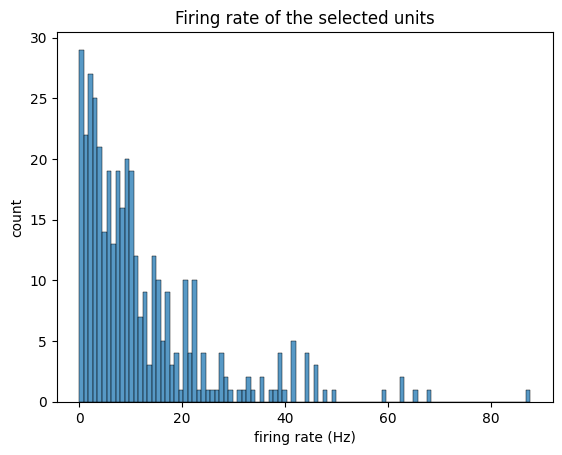

In [7]:
### optionally we can filter the units according to their firing rate
sns.histplot(selected_units['firing_rate'], stat="count", bins=100)

plt.title('Firing rate of the selected units')
plt.xlabel('firing rate (Hz)')
plt.ylabel('count')
plt.show()


##### Select the spikes emitted during the stimuli (all stimuli presented in the session are used)

In [8]:
def stimul_times(session, selected_unit_ids, list_stimulus_type = ['natural_movie_one'], which_block = 1):

    if which_block < 0:
        print("If you want all the block, the parameter which_block=0, otherwise specify the block you are interested")
        print("You can do that by specifying which_block = block_id, where block_id is a positive integer")
        print("The same block_id will be used for all the stimuli")
        return 0

    for stimulus_id, stimulus_type in enumerate(list_stimulus_type):

        print("We are considering stimulus ", stimulus_type)

        df_selected_stimulus = session.stimulus_presentations[
            (session.stimulus_presentations['stimulus_name'] == stimulus_type)
        ]

        #### List of all unique blocks of a given stimulus:
        blocks_for_stimulus_id = df_selected_stimulus['stimulus_block'].unique()
        if which_block > len(blocks_for_stimulus_id):
            print("The block you specified does not exist")
            print("I will take instead the last existing block, that is block number ", len(blocks_for_stimulus_id))

        if which_block > 0:

            block_chosen = which_block - 1
            print("You are considering block_id = which_block - 1 = ", block_chosen)

            #### We can also select all the IDs belonging to a specific block of stimuli (or a specific stimulus condition) of the chosen type
           
            ### starting and ending time of presentaion of a given block of stimuli (a block of stimuli is made of successive presentations)
            ### a session is usually made of several block of a given stimulus type
            start_time = np.min(df_selected_stimulus[df_selected_stimulus['stimulus_block'] == blocks_for_stimulus_id[block_chosen]]['start_time'])
            stop_time = np.max(df_selected_stimulus[df_selected_stimulus['stimulus_block'] == blocks_for_stimulus_id[block_chosen]]['stop_time'])
            print(f'block {blocks_for_stimulus_id[block_chosen]} starts at time {start_time}s and stops at time {stop_time}s')
            print(f'therefore it lasts {(stop_time - start_time) / 60} minutes')

            ### this are the index values corresponding to a given block of a given stimulus
            selected_presentation_ids = session.stimulus_presentations.loc[
                (session.stimulus_presentations['stimulus_name'] == stimulus_type) & 
                (session.stimulus_presentations['stimulus_block'] == blocks_for_stimulus_id[block_chosen])
            ].index.values

        elif which_block == 0: 

            print("You are considering all blocks, that is all the data available for that stimulus")

            total_time = 0
            for block_id, block in enumerate(blocks_for_stimulus_id):
                start_time = np.min(df_selected_stimulus[df_selected_stimulus['stimulus_block'] == blocks_for_stimulus_id[block_id]]['start_time'])
                stop_time = np.max(df_selected_stimulus[df_selected_stimulus['stimulus_block'] == blocks_for_stimulus_id[block_id]]['stop_time'])
                total_time += stop_time - start_time
            print(f'total time for the stimulus is {total_time / 60} minutes')

            # take all specified stimulus independently from block
            selected_presentation_ids = session.stimulus_presentations.loc[
                (session.stimulus_presentations['stimulus_name'] == stimulus_type)
            ].index.values

        ##### here we filter the spike times taking only the spikes occured during the presentation of the desired stimulus type 
        #### (can be more than one experiment, AKA stimulus_presentation_id for each type)
        ##### and for desired units (those previously selected)

        times = session.presentationwise_spike_times(
            stimulus_presentation_ids = selected_presentation_ids,
            unit_ids = selected_unit_ids
        )

        if stimulus_id == 0:
            selected_times = times
        else:
            #### we can concatenate the dataframe corresponding to different presentation types 
            #### (just change 'stimulus_type' above and make a cycle for):
            selected_times = pd.concat([selected_times, times])

    # Sort the concatenated DataFrame by index
    selected_times = selected_times.sort_index()

    print(f'We have {len(selected_times.unit_id)} spikes from {len(selected_times.unit_id.unique())} units')

    return selected_times

In [9]:
list(session.stimulus_presentations['stimulus_name'].unique())

['spontaneous',
 'gabors',
 'flashes',
 'drifting_gratings',
 'natural_movie_three',
 'natural_movie_one',
 'static_gratings',
 'natural_scenes',
 'drifting_gratings_contrast']

In [10]:
#### Neuron-level symbolic sequence: loaded from a local cache if present, otherwise built from the session
NEURON_SEQ_CACHE = f"data/sequences_{SESSION_LABEL}_allstimuli_multinomial.csv"
USE_NEURON_CACHE = os.path.exists(NEURON_SEQ_CACHE)

if not USE_NEURON_CACHE:
    ### spikes of the selected units during all the stimuli presented in the session
    list_stimulus_type = list(session.stimulus_presentations['stimulus_name'].unique())
    selected_times = stimul_times(session, selected_unit_ids, list_stimulus_type, which_block = 0)


### Create and save symbolic sequence to data

In [11]:
### Neuron-level symbolic sequence: one symbol per spike (the unit id), -1 = space
import csv

SAVE_NEURON_CACHE = False  # True: also save the neuron-level sequence to NEURON_SEQ_CACHE (~1.2 GB)

if USE_NEURON_CACHE:
    hyper_symbolic_sequence = []
    spike_symbolic_sequence = []
    with open(NEURON_SEQ_CACHE, 'r') as f:
        reader = csv.reader(f)
        next(reader)  # Skip header row
        for row in reader:
            hyper_symbolic_sequence.append(float(row[0]))
            spike_symbolic_sequence.append(float(row[1]))
    print(f"Loaded {NEURON_SEQ_CACHE}")
else:
    time_bin = 0.0015    # refractory time (s): a space (-1) is inserted between spikes further apart than this
    spacebar = 1
    random_sametime = 1  # simultaneous spikes are put in random order (seeded)
    symba.set_seed(SEED)
    hyper_symbolic_sequence, spike_symbolic_sequence = symba.events_to_symbolic_sequences(
        time_bin, selected_times, spacebar, random_sametime)
    if SAVE_NEURON_CACHE:
        with open(NEURON_SEQ_CACHE, 'w', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(['hyper_symbolic_sequence', 'spike_symbolic_sequence'])
            writer.writerows(zip(hyper_symbolic_sequence, spike_symbolic_sequence))
        print(f"Saved {NEURON_SEQ_CACHE}")

print(len(hyper_symbolic_sequence), len(spike_symbolic_sequence))


Loaded data/sequences_session29_allstimuli_multinomial.csv
40133703 40133703


### converting in hyper brain areas

In [12]:
def remove_repeated(sequence, spikes):
    ### remove the repeated symbols in the sequence
    new_sequence = []
    new_spikes = []
    for i in range(len(sequence)):
        if i == 0:
            new_sequence.append(sequence[i])
            new_spikes.append(spikes[i])
        else:
            if sequence[i] != sequence[i-1]:
                new_sequence.append(sequence[i])
                new_spikes.append(spikes[i])
    return new_sequence, new_spikes


In [13]:
### check that the symbolic sequence is ordered in time (spaces, -1, are skipped)
last_time = None
for t in spike_symbolic_sequence:
    if t == -1:
        continue
    assert last_time is None or t >= last_time, "spike times are not in chronological order"
    last_time = t


In [14]:
### for brain areas

remove_rep = 0

### convert the symbolic sequence of neurons in the symbolic sequence of brain areas
unit_structure_dict = {}
for unit in selected_unit_ids:
    unit_structure_dict[unit] = selected_units.loc[unit, 'structure_acronym']

hyper_symbolic_sequence_area = []
for unit in hyper_symbolic_sequence:
    if unit == -1:
        hyper_symbolic_sequence_area.append('space')
    else:
        # a KeyError here means the neuron-level sequence was built with a different unit selection
        hyper_symbolic_sequence_area.append(unit_structure_dict[unit])

###remove repeated symbols
if remove_rep == 1:
    hyper_symbolic_sequence_area, spike_symbolic_sequence = remove_repeated(hyper_symbolic_sequence_area, spike_symbolic_sequence)


print(len(set(hyper_symbolic_sequence_area)), len(set(unit_structure_dict.values())))


19 18


In [15]:
AREA_SEQ_FILE = f"data/sequences_{SESSION_LABEL}_allstimuli_brainareas_multinomial.csv"
OVERWRITE_AREA_SEQ = False  # this file is the input of the brain section of demo_and_figures.ipynb

if os.path.exists(AREA_SEQ_FILE) and not OVERWRITE_AREA_SEQ:
    print(f"{AREA_SEQ_FILE} already exists; set OVERWRITE_AREA_SEQ = True to overwrite it")
else:
    with open(AREA_SEQ_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['hyper_symbolic_sequence', 'spike_symbolic_sequence'])
        for hyper, spike in zip(hyper_symbolic_sequence_area, spike_symbolic_sequence):
            writer.writerow([hyper, spike])
    print(f"Sequences saved to {AREA_SEQ_FILE}")


data/sequences_session29_allstimuli_brainareas_multinomial.csv already exists; set OVERWRITE_AREA_SEQ = True to overwrite it
